# Netflix Content Strategy - Exploratory Data Analysis

**Business problem:** Analyse the catalogue of Netflix movies and TV shows to help decide **what type of content to produce** and **how to grow the business in different countries**.

**Dataset:** 8,807 titles (as of mid-2021) with type, director, cast, country, date added, release year, rating, duration, genre and description.

**Approach:** structure & quality checks -> unnest multi-value columns (director, cast, country, genre) -> clean missing values -> visual analysis -> business insights -> recommendations.

> Runs top-to-bottom on Google Colab with no installs. If `netflix.csv` is not found the notebook asks you to upload it.

## 1. Setup and data loading

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
os.makedirs("images", exist_ok=True)
RED, GREY = "#B20710", "#4D4D4D"          # Netflix red for Movies/primary, grey for TV Shows
TYPE_PAL = {"Movie": RED, "TV Show": GREY}

for path in ["netflix.csv", "data/netflix.csv"]:
    if os.path.exists(path):
        break
else:
    try:
        from google.colab import files
        print("Upload netflix.csv"); up = files.upload(); path = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError("Place netflix.csv next to this notebook or in ./data/")
data = pd.read_csv(path)
print("Shape:", data.shape)
data.sample(5, random_state=1)

Shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
2894,s2895,TV Show,Puerta 7,NaN,"Dolores Fonzi, Esteban Lamothe, Carlos Belloso, Juan Gil Navarro, Daniel Aráoz, Antonio Grimau, Ignacio Quesada, Mónica Ayos, Daniel Valenzuela",Argentina,"February 21, 2020",2020,TV-MA,1 Season,"Crime TV Shows, International TV Shows, Spanish-Language TV Shows",A determined woman works to rid an Argentine soccer club of the violent crime and corruption surrounding its intense fanbase.
2161,s2162,Movie,Nasha Natasha,Martín Sastre,Natalia Oreiro,Uruguay,"August 6, 2020",2020,TV-PG,72 min,"Documentaries, International Movies, Music & Musicals",Concert and behind-the-scenes footage capture life on tour for Uruguayan sensation Natalia Oreiro as she performs for packed crowds throughout Russia.
6363,s6364,Movie,Born to Be Free,Gayane Petrosyan,"Casting a light on the mistreatment of sea mammals, this documentary follows the plight of 18 Beluga whales kept in captivity for years.","United Kingdom, Russia","April 1, 2017",2016,TV-14,74 min,"Documentaries, International Movies","Casting a light on the mistreatment of sea mammals, this documentary follows the plight of 18 Beluga whales kept in captivity for years."
2575,s2576,TV Show,WWII in HD,NaN,"Gary Sinise, Rob Lowe, Josh Lucas, Justin Bartha, Amy Smart, LL Cool J, Steve Zahn, Jason Ritter, Ron Livingston, Tim DeKay, Mark Hefti, James Kyson, Rob Corddry",United States,"May 2, 2020",2009,TV-14,1 Season,Docuseries,Rare color footage interwoven with firsthand interviews and diary entries bring to life the global sweep of World War II via those who were there.
2698,s2699,TV Show,Hi Score Girl,NaN,"Kohei Amasaki, Sayumi Suzushiro, Yuuki Hirose, Kazuyuki Okitsu, Daiki Yamashita, Daria Midou, Satomi Arai, Shizuka Ito, Cho, Chinatsu Akasaki, Tomokazu Sugita, Yuichi Nakamura, Kana Ueda, Taketora, Hochu Otsuka, Hiroki Yasumoto",Japan,"April 9, 2020",2019,TV-14,2 Seasons,"Anime Series, International TV Shows, Romantic TV Shows","A chronic gamer abysmally inept in academics and sports finally meets his match at his usual shady arcade – and it’s his rich classmate, Akira."


## 2. Structure of the dataset
**Observation:** `director`, `cast`, `country` and `listed_in` store *several values in one cell, separated by commas*.
To analyse by an individual director, actor, country or genre, these columns must be split and stacked into one value per row (done in section 4).

In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [3]:
print("Missing values per column:")
print(data.isna().sum())
print("\nDuplicate titles:", data.title.duplicated().sum())
print("Release year range:", data.release_year.min(), "-", data.release_year.max())

Missing values per column:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Duplicate titles: 0
Release year range: 1925 - 2021


In [4]:
# Non-graphical analysis: value counts of the key categorical columns
for c in ["type", "rating"]:
    print(f"--- {c} ---"); print(data[c].value_counts(dropna=False).to_string(), "\n")
print("Top 5 country strings:\n", data.country.value_counts().head().to_string())

--- type ---
type
Movie      6131
TV Show    2676 

--- rating ---
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1 

Top 5 country strings:
 country
United States     2818
India              972
United Kingdom     419
Japan              245
South Korea        199


## 3. Unnesting multi-value columns
Each column is split on the comma and expanded to one row per value (`str.split` + `explode`), then the four pieces are merged back on `title`.
Note that one title can now appear on many rows, so from here on we count **unique `show_id`s** (`nunique`) rather than rows.

In [5]:
def unnest(col):
    s = data[["title", col]].copy()
    s[col] = s[col].astype(str).str.split(",")
    s = s.explode(col)
    s[col] = s[col].str.strip().replace({"nan": np.nan, "": np.nan})
    return s.reset_index(drop=True)

director_split, cast_split  = unnest("director"), unnest("cast")
country_split, listedin_split = unnest("country"), unnest("listed_in")
for name, df_ in [("director", director_split), ("cast", cast_split), ("country", country_split), ("listed_in", listedin_split)]:
    print(f"{name:10s} -> {len(df_):>6,} rows")

director   ->  9,612 rows
cast       -> 64,951 rows
country    -> 10,850 rows
listed_in  -> 19,323 rows


In [6]:
# Merge the four pieces on title, then bring back the other attributes
merge_listedin_country = listedin_split.merge(country_split, on="title")
merge_cast_director    = director_split.merge(cast_split, on="title")
merge_all = merge_listedin_country.merge(merge_cast_director, on="title")

data_final = data[["show_id", "type", "date_added", "release_year", "rating", "duration", "description", "title"]].merge(merge_all, on="title")
print("Shape after unnesting:", data_final.shape)
data_final.head()

Shape after unnesting: (202065, 12)


,show_id,type,date_added,release_year,rating,duration,description,title,listed_in,country,director,cast
0,s1,Movie,"September 25, 2021",2020,PG-13,90 min,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable.",Dick Johnson Is Dead,Documentaries,United States,Kirsten Johnson,NaN
1,s2,TV Show,"September 24, 2021",2021,TV-MA,2 Seasons,"After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.",Blood & Water,International TV Shows,South Africa,NaN,Ama Qamata
2,s2,TV Show,"September 24, 2021",2021,TV-MA,2 Seasons,"After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.",Blood & Water,International TV Shows,South Africa,NaN,Khosi Ngema
3,s2,TV Show,"September 24, 2021",2021,TV-MA,2 Seasons,"After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.",Blood & Water,International TV Shows,South Africa,NaN,Gail Mabalane
4,s2,TV Show,"September 24, 2021",2021,TV-MA,2 Seasons,"After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.",Blood & Water,International TV Shows,South Africa,NaN,Thabang Molaba


## 4. Duplicates and missing values

In [7]:
print("Duplicate rows:", data_final.duplicated().sum())
data_final = data_final.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", data_final.shape)
print()
print(data_final.isna().sum())

Duplicate rows: 55
Shape after dropping duplicates: (202010, 12)

show_id             0
type                0
date_added        158
release_year        0
rating             67
duration            3
description         0
title               0
listed_in           0
country         12003
director        50643
cast             2149
dtype: int64


**Treatment of missing values**
- `director`, `cast`: filled with *Unknown Director* / *Unknown Cast* (so those titles are not lost; we exclude the placeholders when ranking people).
- `date_added`: 10 titles have no date; filled with **1 January of the release year** (assumption).
- `duration`: 3 Louis C.K. titles have the duration typed into the `rating` column (data-entry error). Move it to `duration` and set rating to missing.
- `rating`: remaining gaps filled with the most common rating (**TV-MA**) for both Movies and TV Shows.
- `country`: filled with **United States** (assumption: the largest producer and Netflix's home market).

In [8]:
data_final["director"] = data_final["director"].fillna("Unknown Director")
data_final["cast"]     = data_final["cast"].fillna("Unknown Cast")

# date_added -> fill with 1 Jan of release year
data_final["date_added"] = data_final["date_added"].fillna("January 1, " + data_final["release_year"].astype(str))

# duration typed into rating (e.g. '74 min')
bad = data_final["duration"].isna()
print("Rows with missing duration:", bad.sum(), "->", data_final.loc[bad, "rating"].unique())
data_final.loc[bad, "duration"] = data_final.loc[bad, "rating"]
data_final.loc[bad, "rating"] = np.nan

# most common rating per type (check, then fill)
print("\nMost common rating by type:")
print(data_final.groupby("type")["rating"].agg(lambda s: s.value_counts().idxmax()))
data_final["rating"] = data_final["rating"].fillna("TV-MA")

data_final["country"] = data_final["country"].fillna("United States")
print("\nRemaining missing values:", int(data_final.isna().sum().sum()))

Rows with missing duration: 3 -> <StringArray>
['74 min', '84 min', '66 min']
Length: 3, dtype: str

Most common rating by type:
type
Movie      TV-MA
TV Show    TV-MA
Name: rating, dtype: str

Remaining missing values: 0


## 5. Date features
`date_added` is a text field. It is converted to a proper date, then split into **year**, **month** and **day** added to Netflix.

In [9]:
data_final["date_added"] = pd.to_datetime(data_final["date_added"].str.strip(), format="mixed")
data_final["year"]  = data_final["date_added"].dt.year
data_final["month"] = data_final["date_added"].dt.strftime("%b")
data_final["day"]   = data_final["date_added"].dt.day
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
data_final["month"] = pd.Categorical(data_final["month"], categories=MONTHS, ordered=True)
for c in ["type", "rating"]:
    data_final[c] = data_final[c].astype("category")

print("Final shape:", data_final.shape)
print("Release year:", data_final.release_year.min(), "to", data_final.release_year.max())
print("Date added:", data_final.date_added.min().date(), "to", data_final.date_added.max().date())
data_final.head(3)

Final shape: (202010, 15)
Release year: 1925 to 2021
Date added: 2003-01-01 to 2021-09-25


,show_id,type,date_added,release_year,rating,duration,description,title,listed_in,country,director,cast,year,month,day
0,s1,Movie,2021-09-25,2020,PG-13,90 min,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable.",Dick Johnson Is Dead,Documentaries,United States,Kirsten Johnson,Unknown Cast,2021,Sep,25
1,s2,TV Show,2021-09-24,2021,TV-MA,2 Seasons,"After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.",Blood & Water,International TV Shows,South Africa,Unknown Director,Ama Qamata,2021,Sep,24
2,s2,TV Show,2021-09-24,2021,TV-MA,2 Seasons,"After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.",Blood & Water,International TV Shows,South Africa,Unknown Director,Khosi Ngema,2021,Sep,24


## 6. Basic statistics

In [10]:
n_unique = data_final.groupby("type", observed=True)["show_id"].nunique()
print("Unique titles:", data_final.show_id.nunique())
print(n_unique.to_string())
print()
print("Top genres (rows):\n", data_final["listed_in"].value_counts().head(5).to_string())
print("\nTop countries (rows):\n", data_final["country"].value_counts().head(5).to_string())
data_final[["release_year", "year", "day"]].describe().round(1)

Unique titles: 8807
type
Movie      6131
TV Show    2676

Top genres (rows):
 listed_in
Dramas                    29787
International Movies      28224
Comedies                  20829
International TV Shows    12845
Action & Adventure        12216

Top countries (rows):
 country
United States     71328
India             22814
United Kingdom    12965
Japan              8679
France             8252


,release_year,year,day
count,202010.0,202010.0,202010.0
mean,2013.4,2019.0,12.2
std,9.0,1.6,9.8
min,1925.0,2003.0,1.0
25%,2012.0,2018.0,1.0
50%,2016.0,2019.0,12.0
75%,2019.0,2020.0,20.0
max,2021.0,2021.0,31.0


## 7. Visual analysis
### 7.1 Movies vs TV Shows

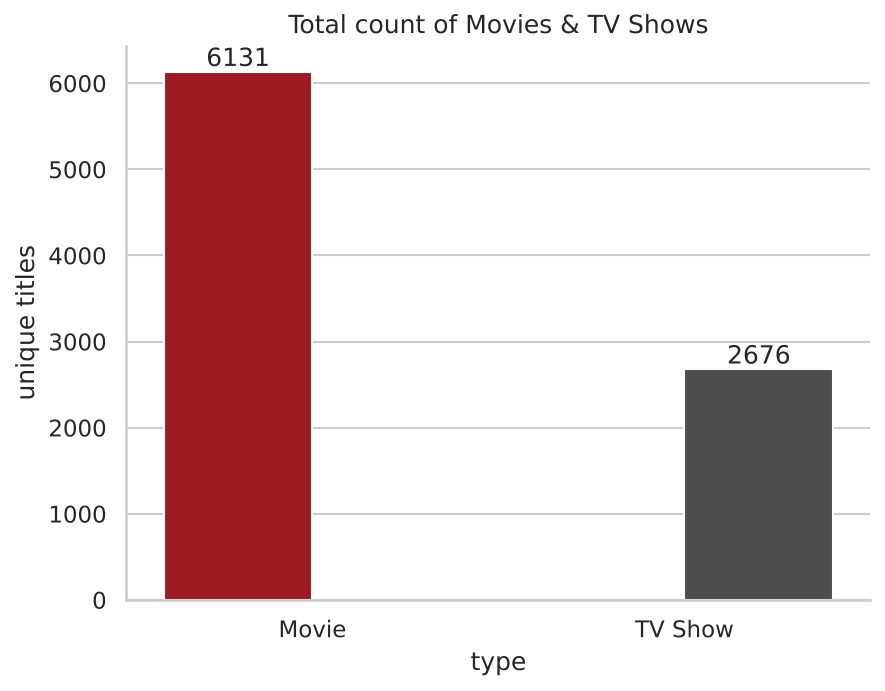

In [11]:
unique_shows = data_final.groupby("type", observed=True)["show_id"].nunique().reset_index()
ax = sns.barplot(x="type", y="show_id", hue="type", data=unique_shows, palette=TYPE_PAL, legend=False)
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
sns.despine(); plt.title("Total count of Movies & TV Shows"); plt.ylabel("unique titles")
plt.savefig("images/01_movies_vs_tv.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight (Plot 1):** The catalogue has more Movies than TV Shows (6,131 vs 2,676 unique titles, about 70% / 30%).

### 7.2 Ratings

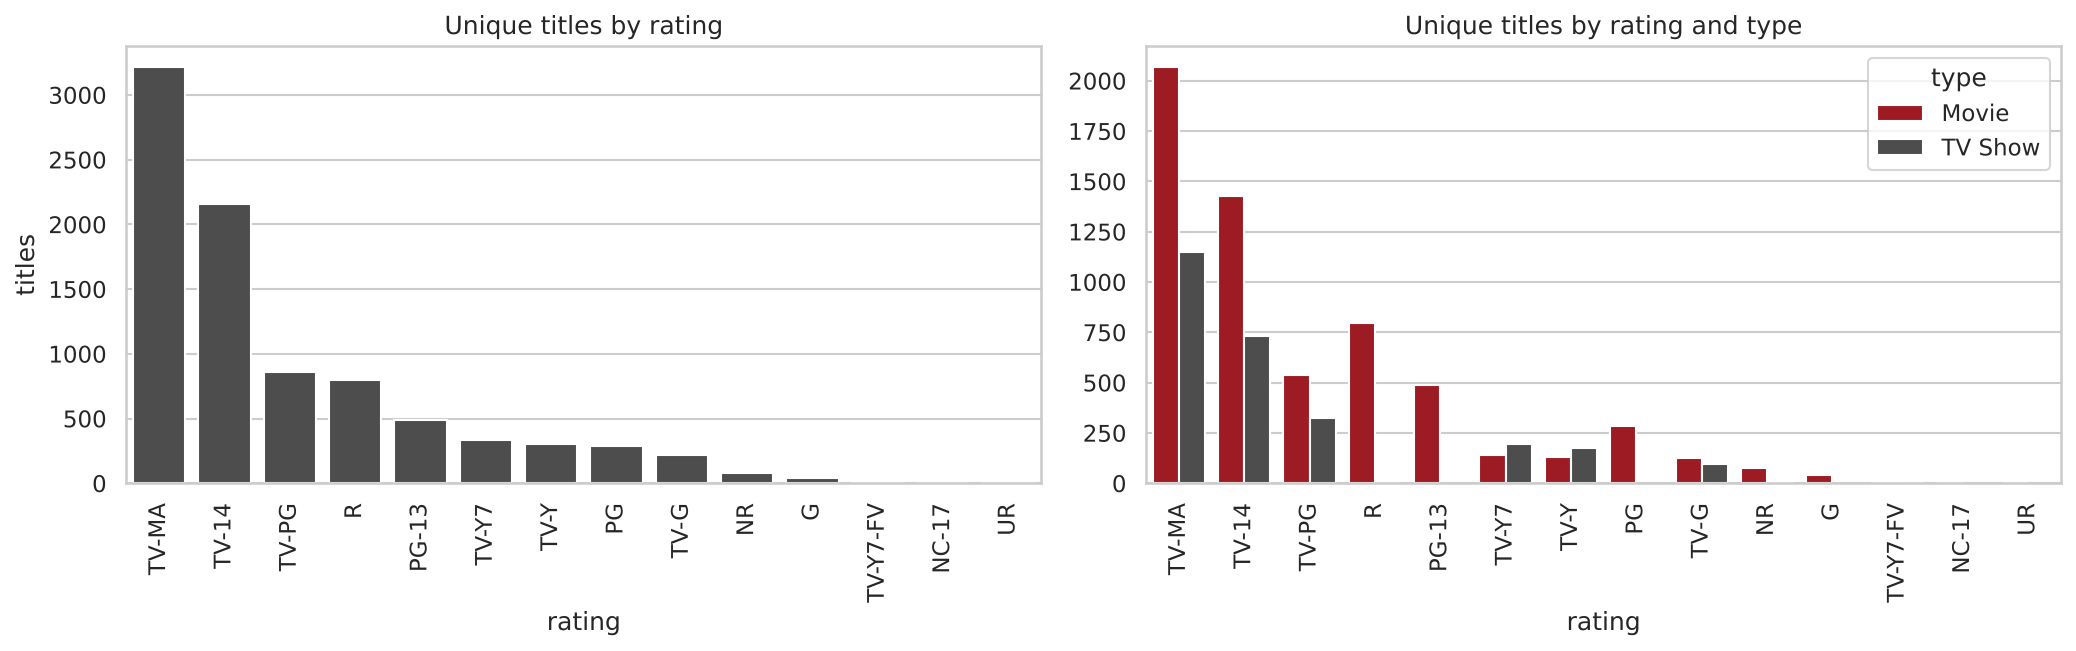

,rating,show_id
8,TV-MA,3214
6,TV-14,2160
9,TV-PG,863
5,R,799
4,PG-13,490


In [12]:
by_rating = data_final.groupby("rating", observed=True)["show_id"].nunique().reset_index().sort_values("show_id", ascending=False)
by_rating_type = data_final.groupby(["rating", "type"], observed=True)["show_id"].nunique().reset_index()
order = by_rating.rating.tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x="rating", y="show_id", data=by_rating, order=order, color=GREY, ax=axes[0])
axes[0].set_title("Unique titles by rating"); axes[0].set_ylabel("titles"); axes[0].tick_params(axis="x", rotation=90)
sns.barplot(x="rating", y="show_id", hue="type", data=by_rating_type, order=order, palette=TYPE_PAL, ax=axes[1])
axes[1].set_title("Unique titles by rating and type"); axes[1].set_ylabel(""); axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.savefig("images/02_ratings.png", dpi=150, bbox_inches="tight"); plt.show()
by_rating.head()

**Insights (Plots 2 & 3):** TV-MA is the most frequent rating, followed by TV-14, TV-PG and R. TV-MA is more common among Movies than TV Shows, followed by TV-14.
Netflix's catalogue is therefore skewed towards mature/teen audiences.

### 7.3 Countries

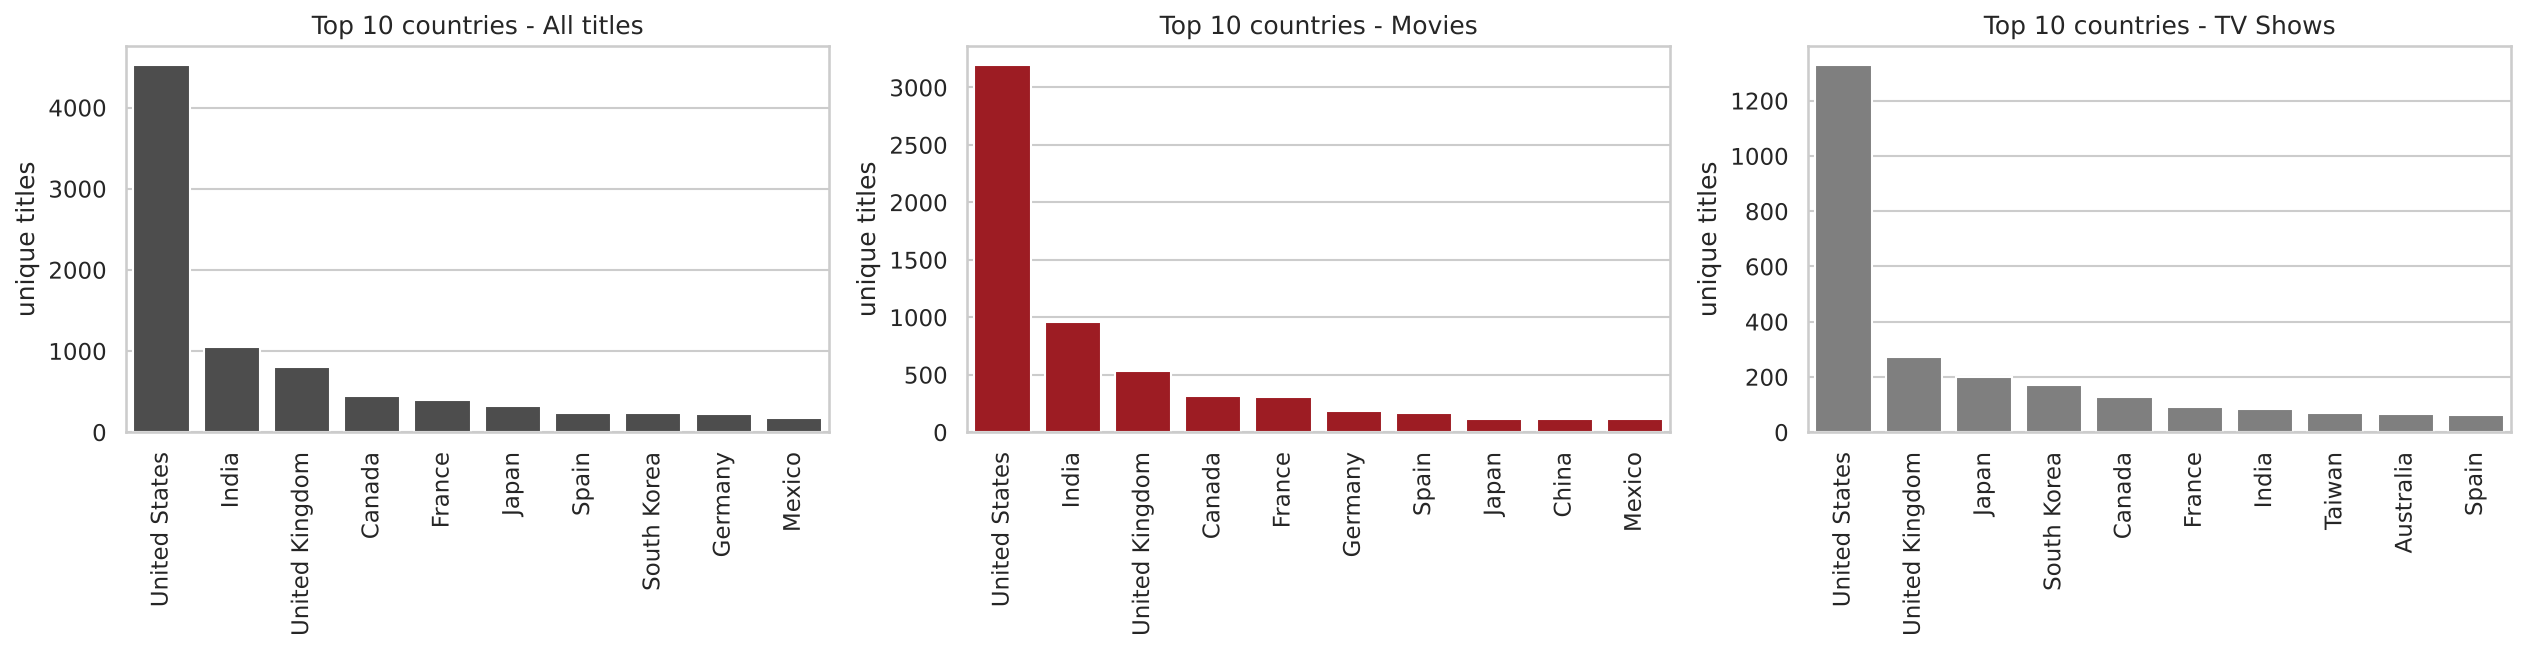

,country,show_id
115,United States,4527
45,India,1046
114,United Kingdom,806
20,Canada,445
36,France,393
53,Japan,318
102,Spain,232
100,South Korea,231
38,Germany,226
67,Mexico,169


In [13]:
def top_countries(df, n=10):
    return (df.groupby("country")["show_id"].nunique().reset_index().sort_values("show_id", ascending=False).head(n))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=False)
for ax, (title, df_, col) in zip(axes, [("All titles", data_final, GREY),
                                         ("Movies", data_final[data_final.type == "Movie"], RED),
                                         ("TV Shows", data_final[data_final.type == "TV Show"], "#7F7F7F")]):
    t = top_countries(df_)
    sns.barplot(x="country", y="show_id", data=t, color=col, ax=ax)
    ax.set_title(f"Top 10 countries - {title}"); ax.set_xlabel(""); ax.set_ylabel("unique titles"); ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.savefig("images/03_top_countries.png", dpi=150, bbox_inches="tight"); plt.show()
top_countries(data_final)

**Insight (Plot 4):** The United States has the most titles, followed by India and the United Kingdom. In the Movie category the order is US then India;
in TV Shows it is US then UK.
*Caveat:* missing countries were filled with the United States, which slightly inflates the US share.

### 7.4 Release years

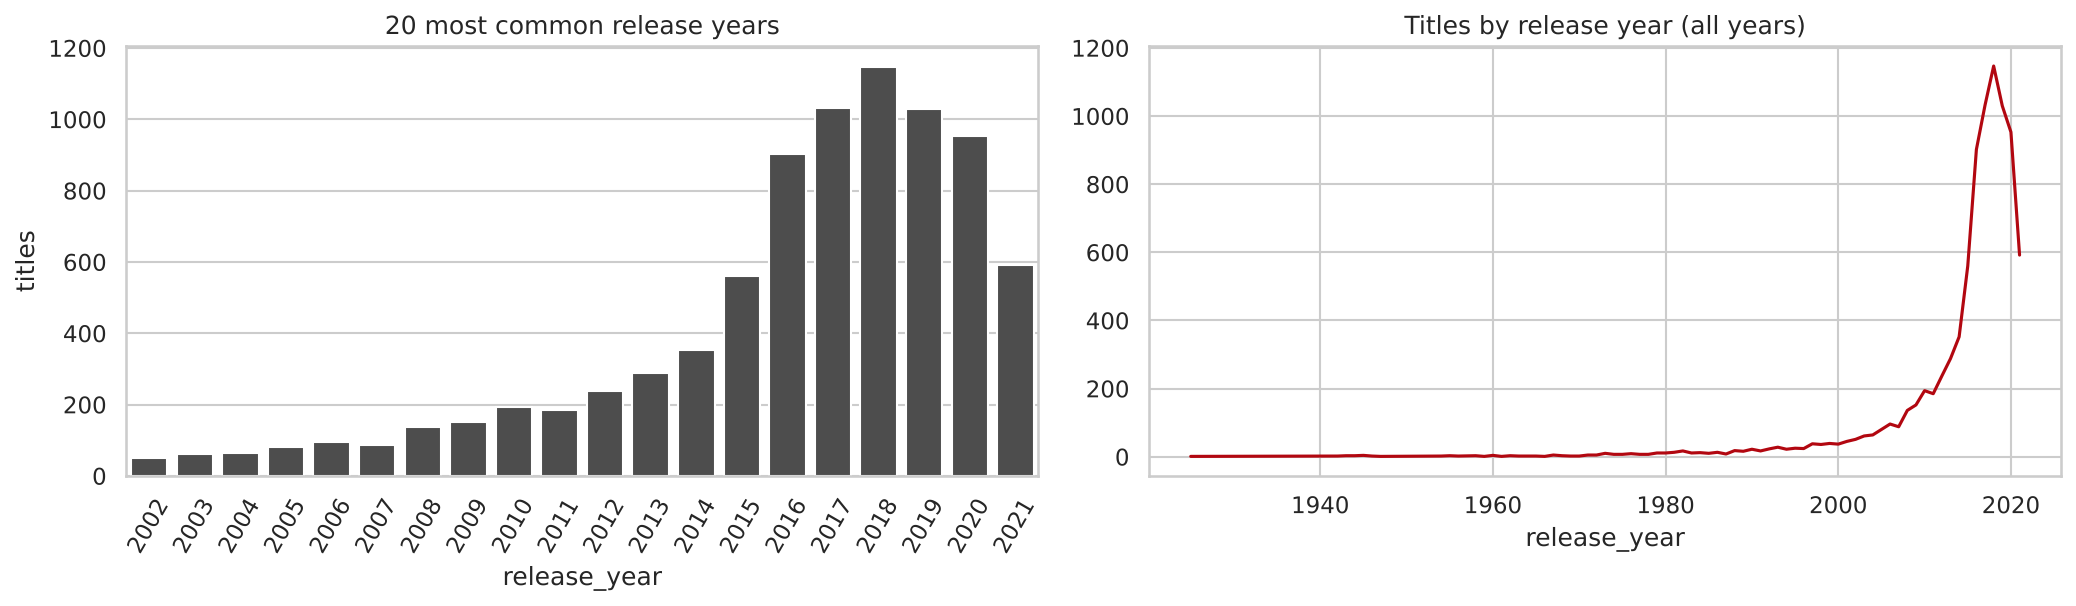

,release_year,show_id
70,2018,1147
69,2017,1032
71,2019,1030
72,2020,953
68,2016,902


In [14]:
shows_by_year = data_final.groupby("release_year")["show_id"].nunique().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.barplot(x="release_year", y="show_id", data=shows_by_year.sort_values("show_id", ascending=False).head(20), color=GREY, ax=axes[0])
axes[0].set_title("20 most common release years"); axes[0].tick_params(axis="x", rotation=60); axes[0].set_ylabel("titles")
sns.lineplot(x="release_year", y="show_id", data=shows_by_year, color=RED, ax=axes[1])
axes[1].set_title("Titles by release year (all years)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig("images/04_release_years.png", dpi=150, bbox_inches="tight"); plt.show()
shows_by_year.sort_values("show_id", ascending=False).head(5)

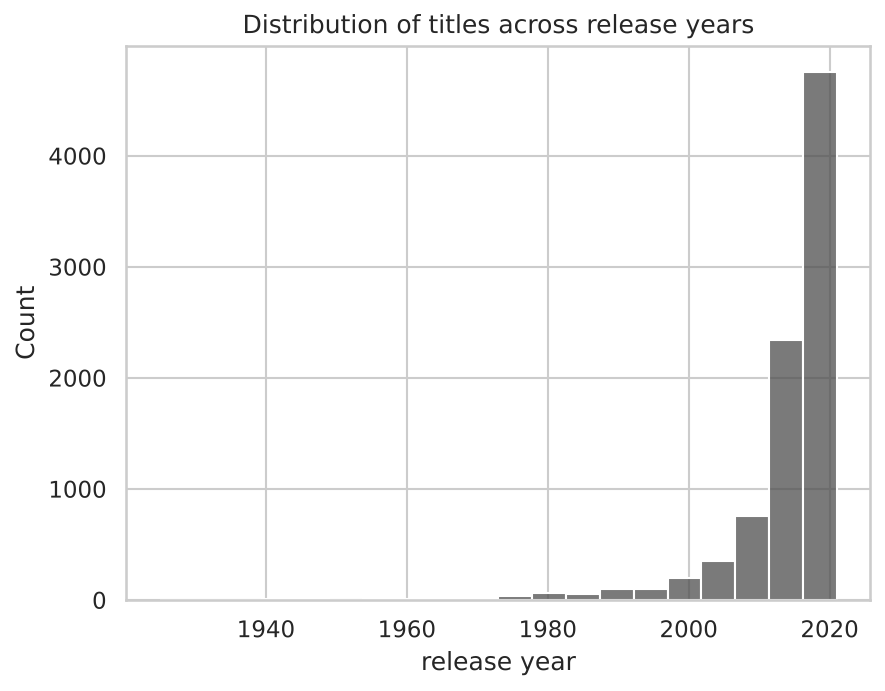

In [15]:
sns.histplot(shows_by_year["release_year"].repeat(shows_by_year["show_id"]), bins=20, color=GREY)
plt.title("Distribution of titles across release years"); plt.xlabel("release year")
plt.savefig("images/05_release_hist.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight (Plot 5):** 2018 is the year with the most releases, followed by 2017 and 2019. The histogram is heavily left-skewed:
the catalogue is dominated by recent titles (post-2015), with a long thin tail of older content.

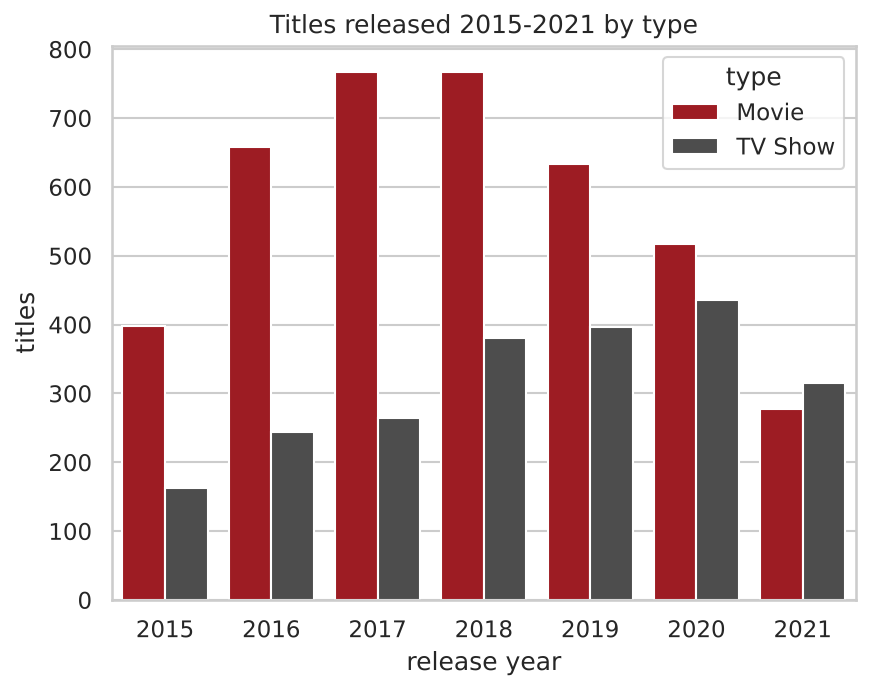

type,Movie,TV Show
release_year,,
2015,398,162
2016,658,244
2017,767,265
2018,767,380
2019,633,397
2020,517,436
2021,277,315


In [16]:
recent = (data_final[data_final.release_year >= 2015].groupby(["release_year", "type"], observed=True)["show_id"].nunique().reset_index())
sns.barplot(x="release_year", y="show_id", hue="type", data=recent, palette=TYPE_PAL)
plt.title("Titles released 2015-2021 by type"); plt.xlabel("release year"); plt.ylabel("titles")
plt.savefig("images/06_recent_releases.png", dpi=150, bbox_inches="tight"); plt.show()
recent.pivot(index="release_year", columns="type", values="show_id")

**Insight (Plot 6):** From 2015 to 2020 more Movies than TV Shows were released each year, with the peak in 2017-2018. In **2021** (partial year in the data) TV Shows (315) overtook Movies (277).
The gap between the two has been narrowing every year since 2018, suggesting a growing focus on TV Shows.

### 7.5 Genres

               listed_in  show_id
11  International Movies     2752
7                 Dramas     2427
4               Comedies     1674
6          Documentaries      869
0     Action & Adventure      859
                 listed_in  show_id
5   International TV Shows     1351
15               TV Dramas      763
14             TV Comedies      581
3           Crime TV Shows      470
6                 Kids' TV      451


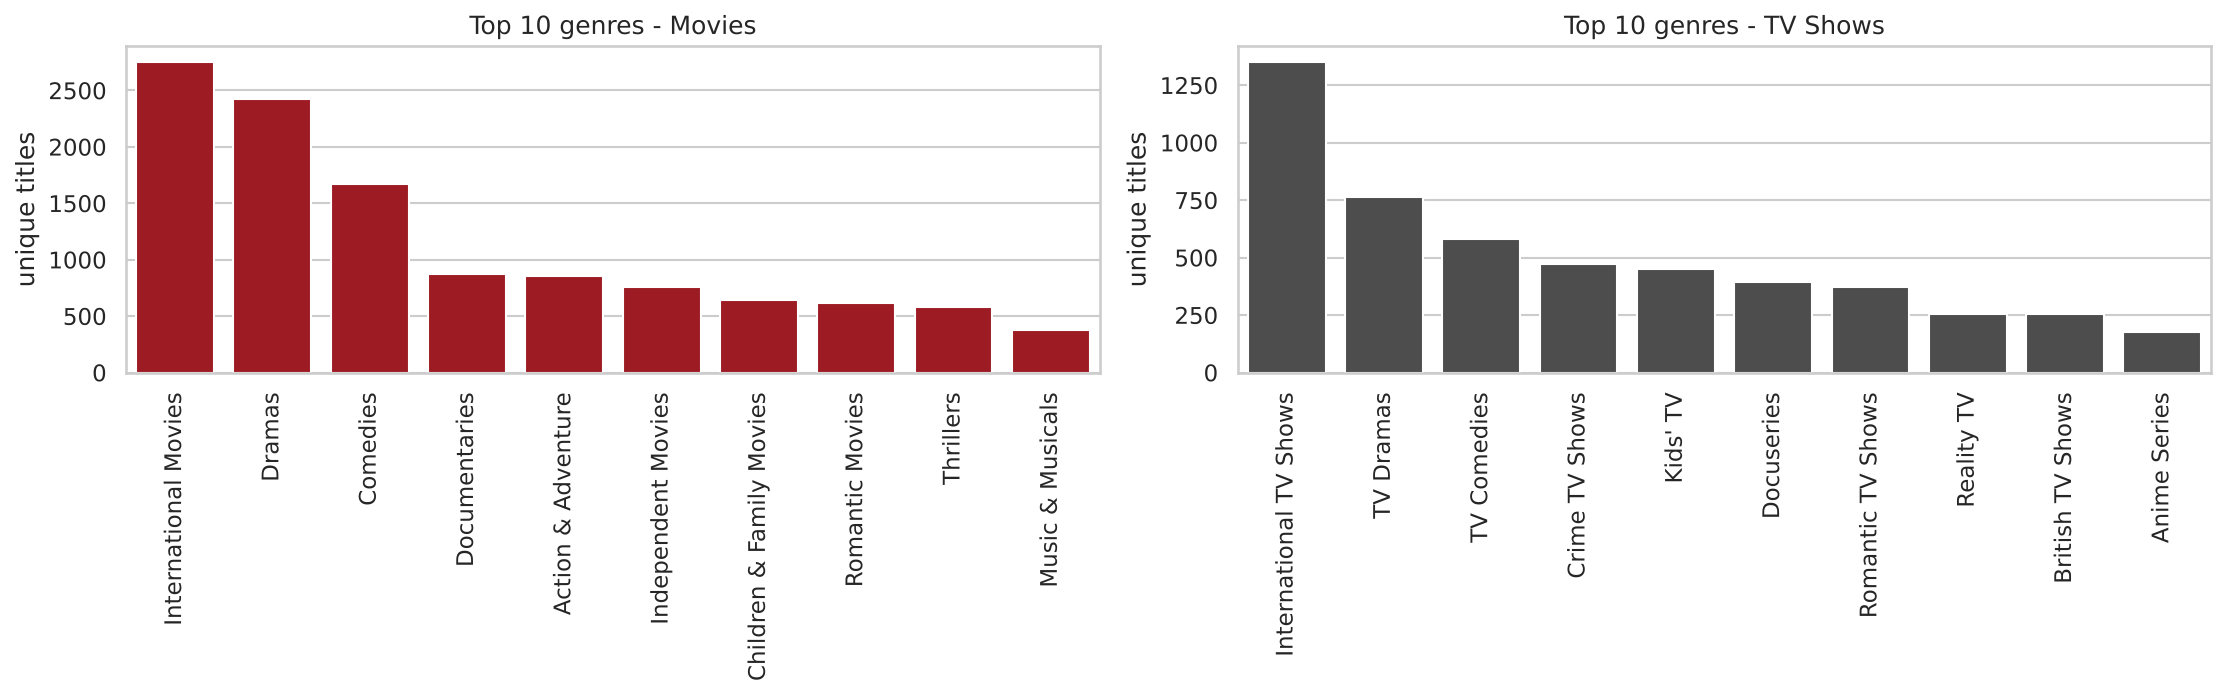

In [17]:
def top_genres(t, n=10):
    return (data_final[data_final.type == t].groupby("listed_in")["show_id"].nunique().reset_index().sort_values("show_id", ascending=False).head(n))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.barplot(x="listed_in", y="show_id", data=top_genres("Movie"), color=RED, ax=axes[0]); axes[0].set_title("Top 10 genres - Movies")
sns.barplot(x="listed_in", y="show_id", data=top_genres("TV Show"), color=GREY, ax=axes[1]); axes[1].set_title("Top 10 genres - TV Shows")
for ax in axes: ax.set_xlabel(""); ax.set_ylabel("unique titles"); ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.savefig("images/07_top_genres.png", dpi=150, bbox_inches="tight"); plt.show()
display(top_genres("Movie", 5)); display(top_genres("TV Show", 5))

**Insight (Plots 7 & 8):** *International Movies* is the most common Movie genre, followed by *Dramas*; *International TV Shows* is the most common TV genre, followed by *TV Dramas*.
(A title can carry several genre tags, so genre counts overlap.) Content made outside the US is a core part of the catalogue.

## 8. When was content added to Netflix?
### 8.1 Titles added per year

In [18]:
added_year = data_final.groupby("year")["show_id"].nunique().reset_index().sort_values("show_id", ascending=False)
print(added_year.head(8).to_string(index=False))

 year  show_id
 2019     2016
 2020     1879
 2018     1650
 2021     1498
 2017     1188
 2016      430
 2015       84
 2014       24


**Observation:** Additions were negligible before 2016 and then rose sharply, peaking in 2019. We therefore focus on **2016-2021**.

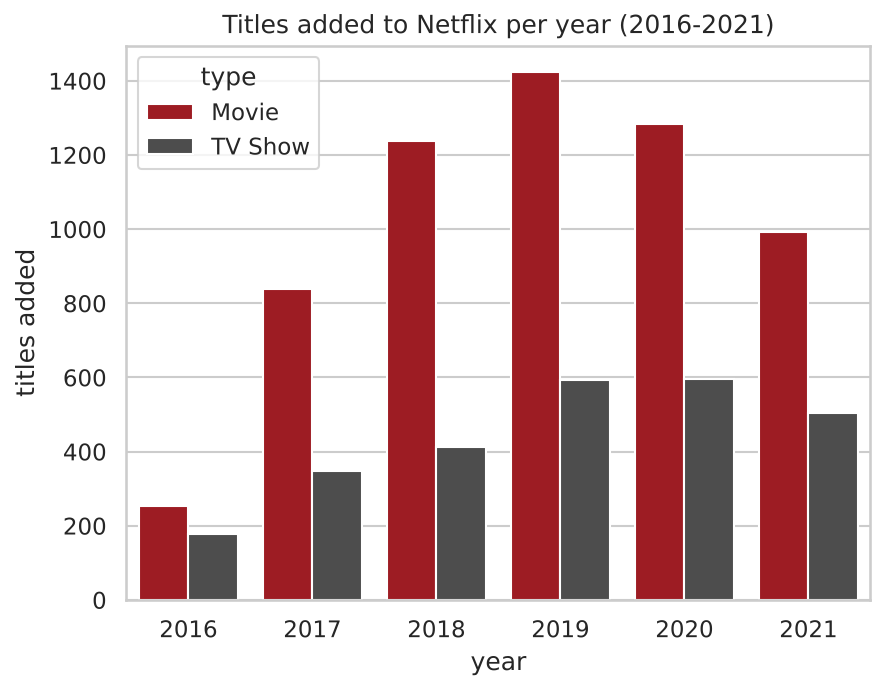

type,Movie,TV Show
year,,
2016,253,177
2017,839,349
2018,1237,413
2019,1424,592
2020,1284,595
2021,993,505


In [19]:
added_yt = data_final.groupby(["year", "type"], observed=True)["show_id"].nunique().reset_index()
added_yt = added_yt[added_yt.year >= 2016]
sns.barplot(x="year", y="show_id", hue="type", data=added_yt, palette=TYPE_PAL)
plt.title("Titles added to Netflix per year (2016-2021)"); plt.ylabel("titles added")
plt.savefig("images/08_added_per_year.png", dpi=150, bbox_inches="tight"); plt.show()
added_yt.pivot(index="year", columns="type", values="show_id")

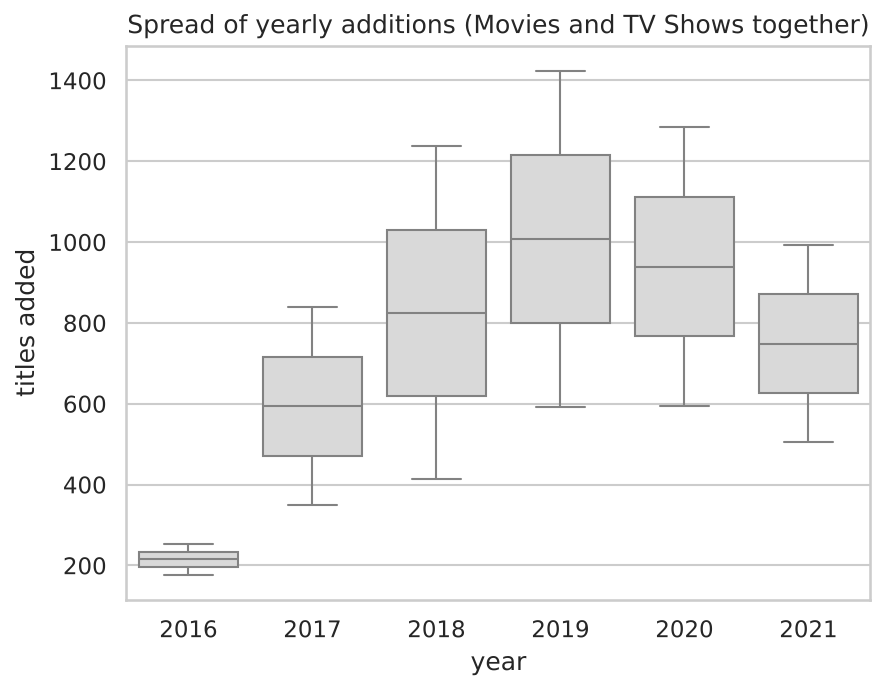

In [20]:
sns.boxplot(x="year", y="show_id", data=added_yt, color="#d9d9d9")
plt.title("Spread of yearly additions (Movies and TV Shows together)"); plt.ylabel("titles added")
plt.savefig("images/09_added_boxplot.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight (Plots 9 & 10):** 2019 is the peak year of additions (Movies 1,424; TV Shows 592). Movies dominate every year. The 2021 figures only cover part of the year.
Year on year, additions grew for both types until 2019 and then eased in 2020-2021 (the 2020 count is lower than 2019 for Movies).
*Note:* 2020 TV additions (595) were the highest of any year, so TV Shows held steady while Movies declined.

### 8.2 Which genres and months? (2016-2021)

In [21]:
since16 = data_final[data_final.year >= 2016]
def genre_month(t):
    g = since16[since16.type == t].groupby(["listed_in", "month"], observed=True)["show_id"].nunique().reset_index()
    return g.sort_values("show_id", ascending=False)
display(genre_month("Movie").head(10)); display(genre_month("TV Show").head(10))

                listed_in month  show_id
135  International Movies   Apr      265
141  International Movies   Oct      257
134  International Movies   Mar      254
143  International Movies   Dec      249
138  International Movies   Jul      244
137  International Movies   Jun      240
139  International Movies   Aug      238
86                 Dramas   Mar      235
140  International Movies   Sep      233
90                 Dramas   Jul      233
                 listed_in month  show_id
68  International TV Shows   Dec      139
63  International TV Shows   Jul      135
64  International TV Shows   Aug      131
62  International TV Shows   Jun      130
60  International TV Shows   Apr      127
67  International TV Shows   Nov      110
59  International TV Shows   Mar      108
65  International TV Shows   Sep      104
66  International TV Shows   Oct      102
61  International TV Shows   May       91


**Insight:** Between 2016 and 2021, *International Movies* (Movies) and *International TV Shows* (TV Shows) account for the top genre-month combinations (Dramas is the other big Movie genre).
International content is consistently what Netflix adds most.

### 8.3 Best time to launch: additions by month

Titles added per month (highest first):
month
Jul    827
Dec    813
Sep    770
Apr    764
Oct    760
Aug    755
Jan    748
Mar    742
Jun    728
Nov    705
May    632
Feb    563


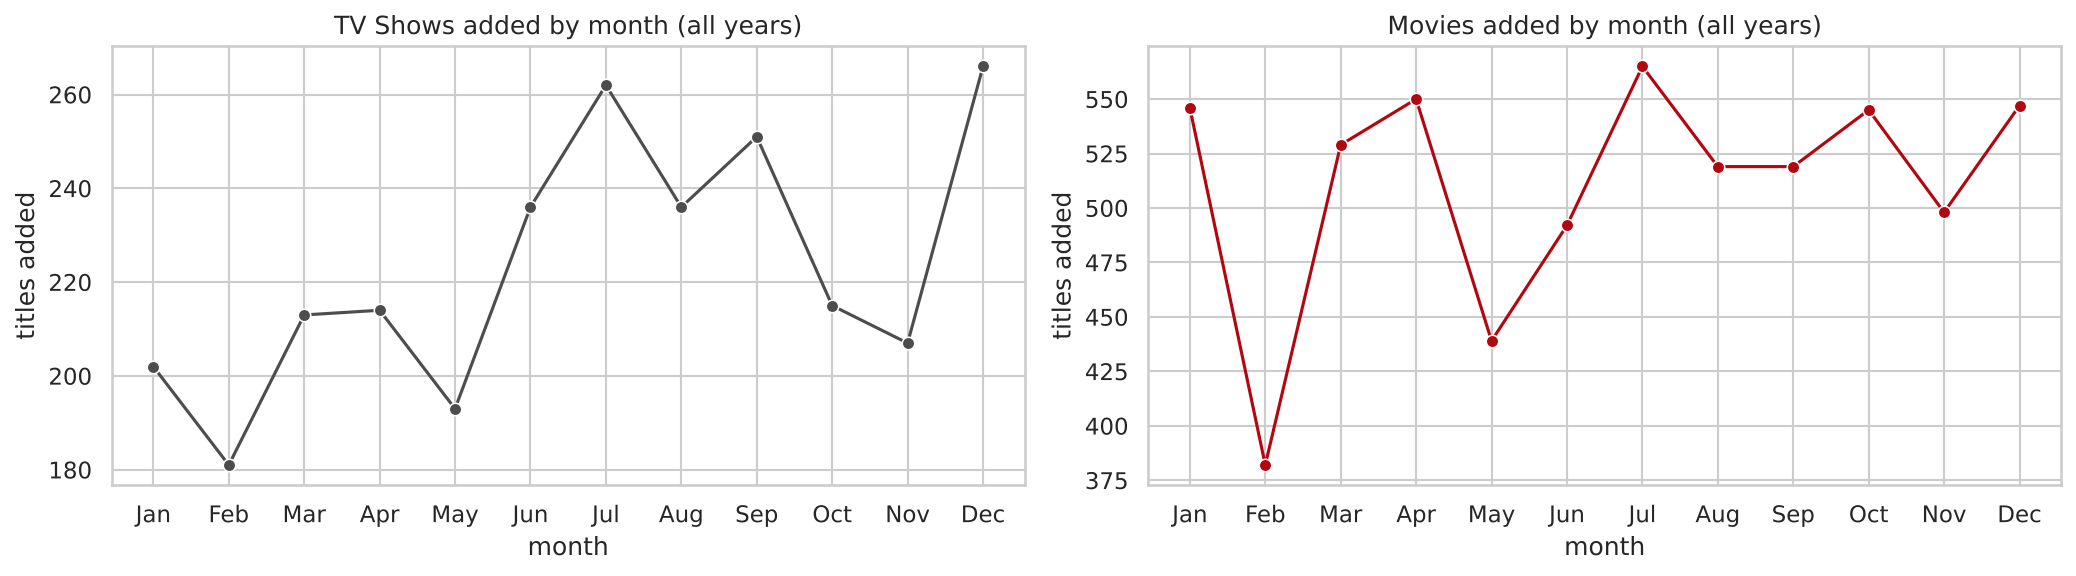

In [22]:
m = (data_final.groupby(["month", "type"], observed=True)["show_id"].nunique().reset_index())
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, t, col in zip(axes, ["TV Show", "Movie"], [GREY, RED]):
    d_ = m[m.type == t]
    sns.lineplot(x="month", y="show_id", data=d_, marker="o", color=col, ax=ax)
    ax.set_title(f"{t}s added by month (all years)"); ax.set_xlabel("month"); ax.set_ylabel("titles added")
plt.tight_layout(); plt.savefig("images/10_added_by_month.png", dpi=150, bbox_inches="tight"); plt.show()
tot = data_final.groupby("month", observed=True)["show_id"].nunique().sort_values(ascending=False)
print("Titles added per month (highest first):"); print(tot.to_string())

**Insight:** July and December see the most additions, with April, September and October close behind; **February is the quietest month**.
Holiday and vacation periods (December, mid-year) are when Netflix adds the most content, plausibly because people have more leisure time and these are strong marketing windows.
(The reasons are interpretation, not something the dataset proves.)

## 9. Actors, directors and long-running shows

                   cast  show_id
2832        Anupam Kher       43
30489    Shah Rukh Khan       35
16697     Julie Tejwani       33
32591  Takahiro Sakurai       32
24215  Naseeruddin Shah       32
28974      Rupa Bhimani       31
25424           Om Puri       30
845        Akshay Kumar       30
35880         Yuki Kaji       29
1773   Amitabh Bachchan       28
                 director  show_id
3749        Rajiv Chilaka       22
1906            Jan Suter       21
3800          Raúl Campos       19
4457          Suhas Kadav       16
2866         Marcus Raboy       16
1954            Jay Karas       15
755   Cathy Garcia-Molina       13
2945      Martin Scorsese       12
1951          Jay Chapman       12
4941      Youssef Chahine       12


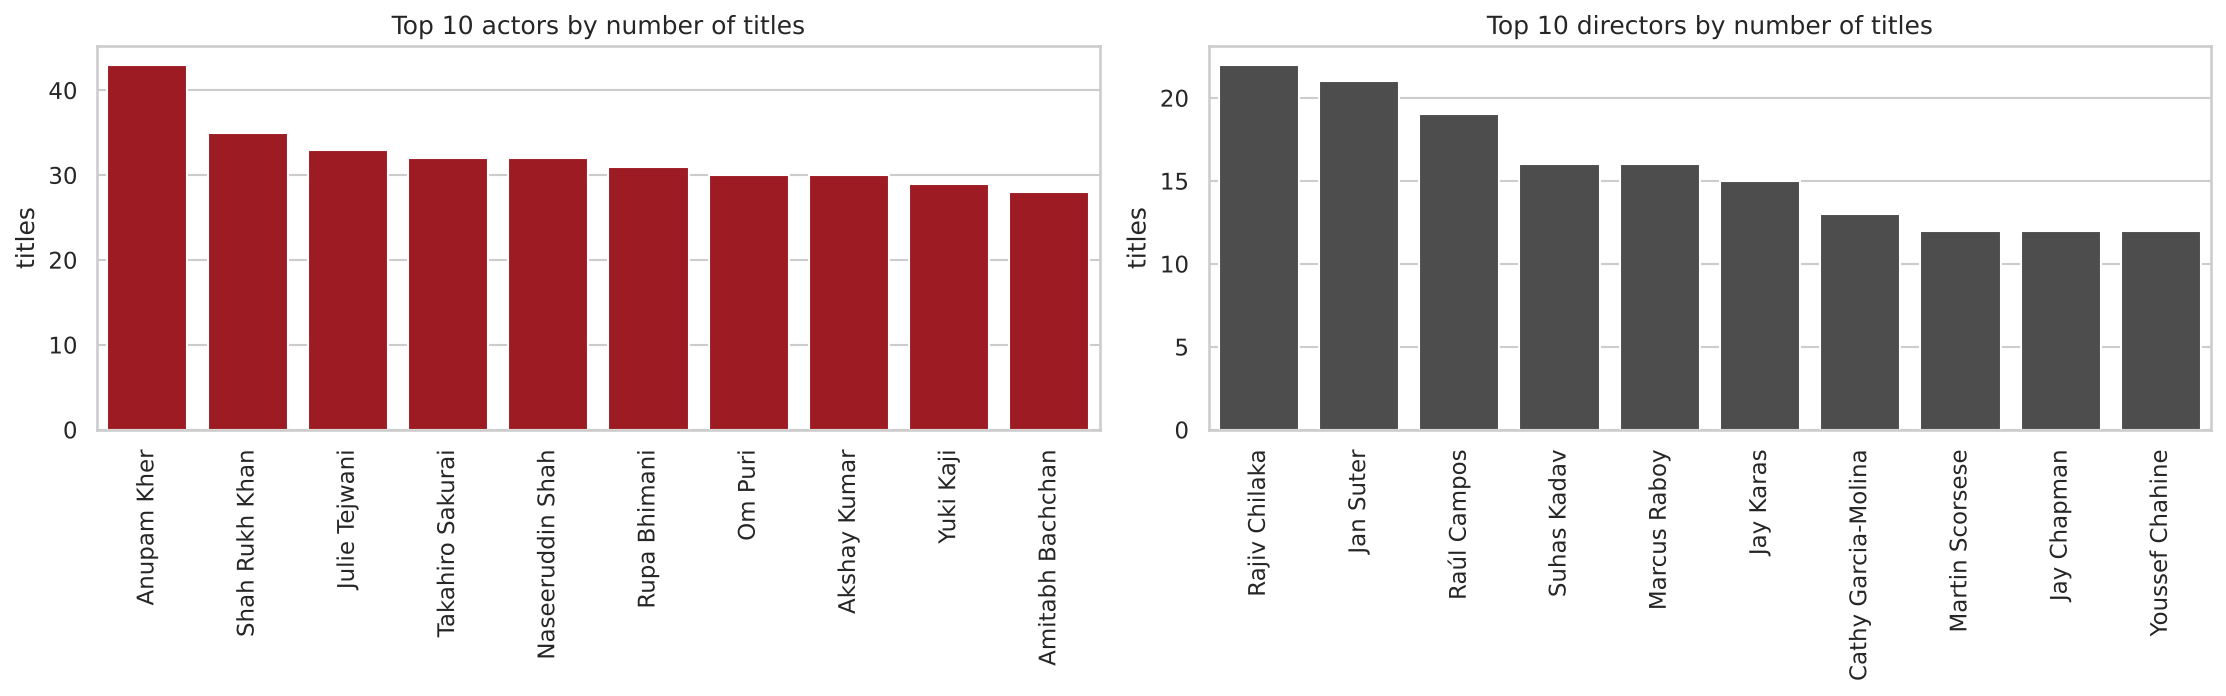

In [23]:
actors = (data_final[data_final.cast != "Unknown Cast"].groupby("cast")["show_id"].nunique().reset_index().sort_values("show_id", ascending=False).head(10))
directors = (data_final[data_final.director != "Unknown Director"].groupby("director")["show_id"].nunique().reset_index().sort_values("show_id", ascending=False).head(10))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.barplot(x="cast", y="show_id", data=actors, color=RED, ax=axes[0]); axes[0].set_title("Top 10 actors by number of titles")
sns.barplot(x="director", y="show_id", data=directors, color=GREY, ax=axes[1]); axes[1].set_title("Top 10 directors by number of titles")
for ax in axes: ax.set_xlabel(""); ax.set_ylabel("titles"); ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.savefig("images/11_actors_directors.png", dpi=150, bbox_inches="tight"); plt.show()
display(actors); display(directors)

**Insight:** The most frequent actors are Indian film stars (Anupam Kher, Shah Rukh Khan, Naseeruddin Shah, Om Puri, Akshay Kumar, Amitabh Bachchan) and dubbing/anime voice actors (Julie Tejwani, Rupa Bhimani, Takahiro Sakurai, Yuki Kaji).
The most frequent directors include children's-content and stand-up specialists (Rajiv Chilaka, Jan Suter, Raul Campos, Marcus Raboy) and filmmakers such as Martin Scorsese.

In [24]:
# TV shows with the most seasons
tv = data_final[data_final.type == "TV Show"].drop_duplicates("show_id").copy()
tv["seasons"] = tv["duration"].str.extract(r"(\d+)").astype(int)
tv.sort_values("seasons", ascending=False)[["title", "seasons"]].head(6).reset_index(drop=True)

,title,seasons
0,Grey's Anatomy,17
1,NCIS,15
2,Supernatural,15
3,Heartland,13
4,COMEDIANS of the world,13
5,Red vs. Blue,13


## 10. Where should Netflix focus? Top countries for additions 2016-2021

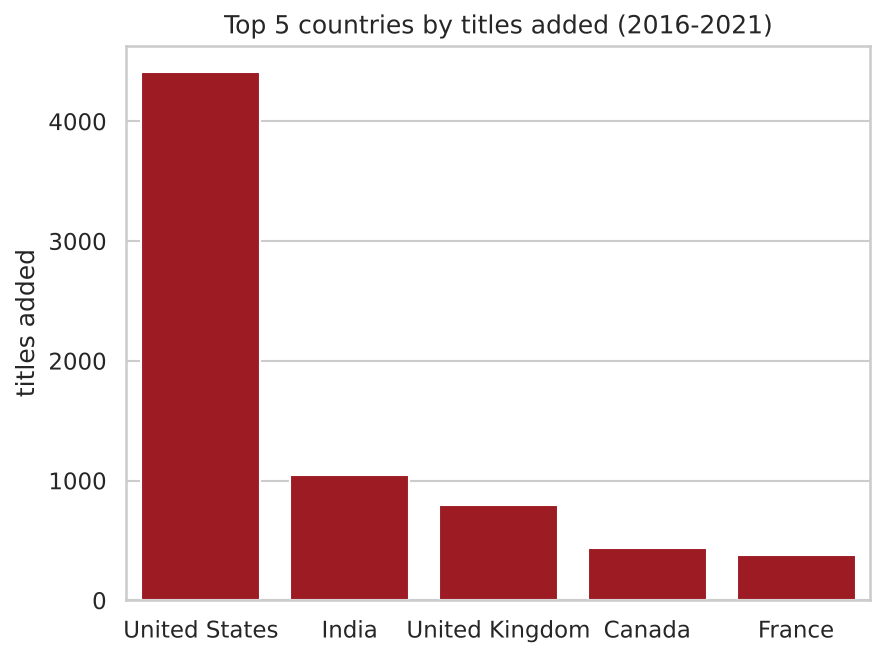

,country,show_id
113,United States,4410
43,India,1046
112,United Kingdom,792
19,Canada,435
34,France,382


In [25]:
top5 = since16.groupby("country")["show_id"].nunique().reset_index().sort_values("show_id", ascending=False).head(5)
sns.barplot(x="country", y="show_id", data=top5, color=RED)
plt.title("Top 5 countries by titles added (2016-2021)"); plt.ylabel("titles added"); plt.xlabel("")
plt.savefig("images/12_top5_countries_added.png", dpi=150, bbox_inches="tight"); plt.show()
top5

**Insight:** Most titles added in 2016-2021 came from the United States and India, followed by the UK, Canada and France.

### Categorical overview

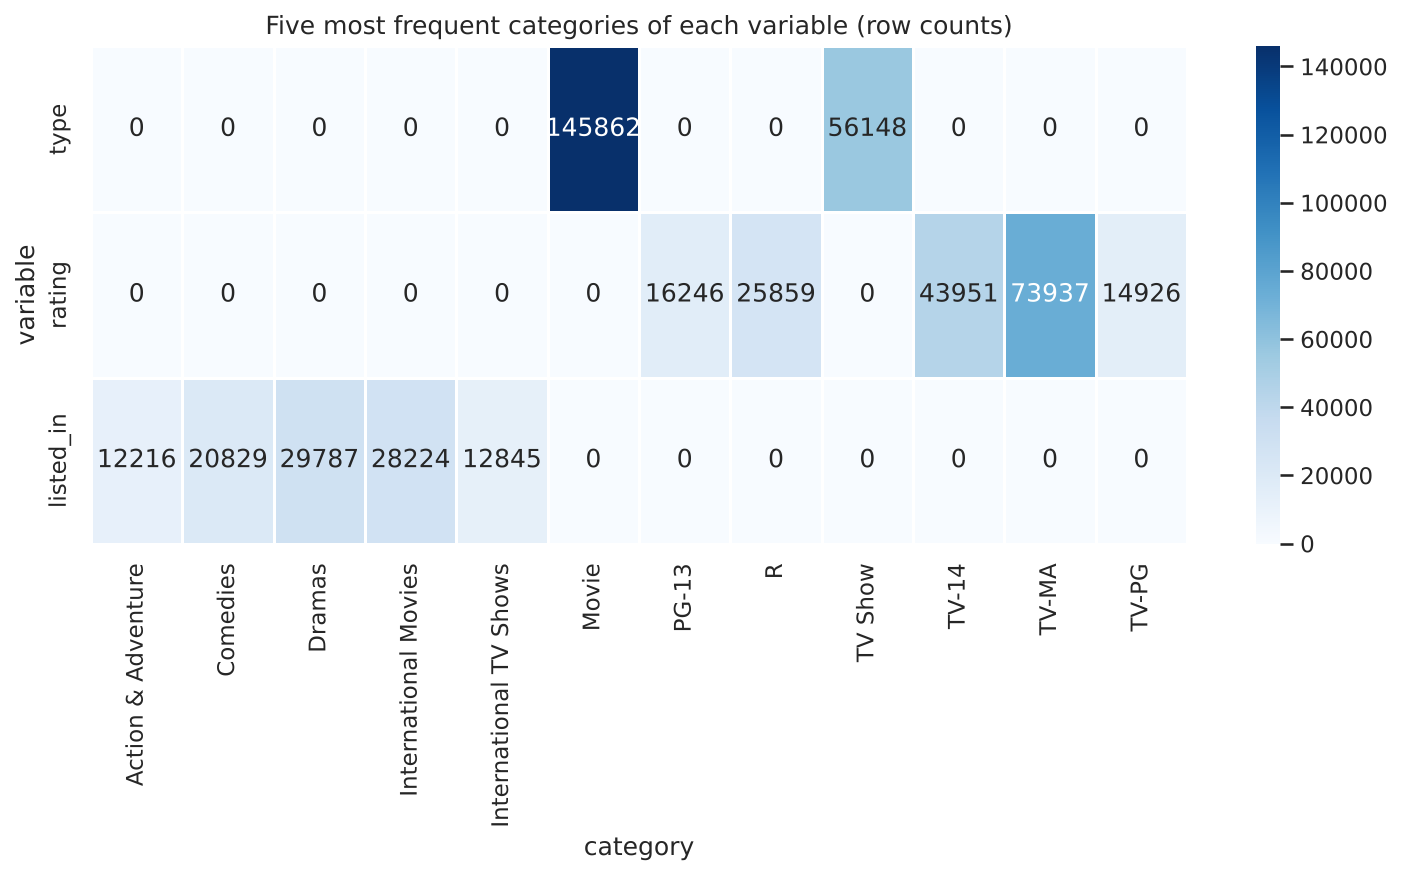

In [26]:
cats = ["type", "rating", "listed_in"]
freq = data_final[cats].apply(lambda x: x.value_counts()[:5]).T.fillna(0)
plt.figure(figsize=(10, 6))
sns.heatmap(freq, annot=True, fmt="g", cmap="Blues", linewidths=.5)
plt.title("Five most frequent categories of each variable (row counts)"); plt.xlabel("category"); plt.ylabel("variable")
plt.tight_layout(); plt.savefig("images/13_categorical_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

## 11. Business insights
1. **Movies outnumber TV Shows about 70/30**, but TV Shows are catching up: in 2021 more TV Shows than Movies were released.
2. **International content is the core of the catalogue.** International Movies and International TV Shows are the top genres in every month.
3. **The US and India lead supply**, followed by the UK, Canada and France.
4. **Mature content dominates.** TV-MA and TV-14 are the most common ratings.
5. **Additions peaked in 2019**; the largest months are July and December, the smallest February.
6. **Content is concentrated in recent years** (post-2015), with a thin catalogue of older titles.

## 12. Recommendations
1. **Prioritise international movies and TV shows** - they are the most-added genres in every month and year.
2. **Double down on the US and India, and widen to the next markets** (UK, Canada and France, then Japan, Spain and South Korea, which already rank next by number of titles) to diversify the catalogue.
3. **Time big launches for December and the mid-year holiday window (July)**; use quieter months such as February for smaller releases or catch-up content.
4. **Build around proven talent.** The most frequent actors and directors show where audiences and supply are concentrated; deepen partnerships with them and with local creators in key regions.
5. **Keep growing TV Shows.** With recent releases tilting toward series, invest in original series that can run for multiple seasons.
6. **Balance the ratings mix.** With most content rated for mature/teen viewers, add more family and kids' content to widen the audience.

## 13. Limitations
- The data lists what is *available*, not what is *watched*; there is no viewership, revenue or subscriber data, so recommendations show catalogue patterns, not proven demand.
- Missing countries (about 6% of rows after unnesting) were assumed to be the United States, which may overstate the US share.
- Genre and country counts overlap because a title can have several tags.
- 2021 is a partial year.